# AgriPulse 02: Shock classification and regression baseline

**Task:** predict `is_shock` (yield ≥ 15 % below the country's previous-5-year baseline) for a
country x crop x year.

**Leakage-safe protocol**

| step | data | purpose |
|---|---|---|
| time-ordered hold-out | train 1990-2007, test 2008-2013 | final scores, never used for any choice |
| forward-chaining CV | inside the training years: validate on 2000-01, 2002-03, 2004-05, 2006-07, each time training only on earlier years | model comparison and decision threshold |
| threshold | the cut-off that maximises F1 on the pooled out-of-fold CV predictions | keeps the minority class visible at a 10 % base rate |

Every feature is known before the harvest of the predicted year: the year's climate observations,
pesticide use, and last year's yield outcome. No current-year yield value is used.

Classifiers (as in the proposal): Decision Tree (with IF-THEN rules), Naive Bayes, k-Nearest Neighbors,
Bagging and AdaBoost. Linear regression is the baseline for the continuous yield change.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

from src import config as cfg
from src.mining import helpers as mn, plotting as viz
from src.mining.data import load_ml_dataset

viz.apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.3f}".format)
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

In [2]:
ml = mn.prepare(load_ml_dataset())
train, test = mn.split_train_test(ml)

pd.DataFrame({
    "years": [f"{train.year.min()}-{train.year.max()}", f"{test.year.min()}-{test.year.max()}"],
    "rows": [len(train), len(test)],
    "shocks": [train.is_shock.sum(), test.is_shock.sum()],
    "shock_rate": [train.is_shock.mean(), test.is_shock.mean()],
}, index=["train", "test"])

,years,rows,shocks,shock_rate
train,1990-2007,12094,1273,0.105
test,2008-2013,4245,394,0.093


## 1. Feature sets (ablation)

The three proposal features are tested alone first. Context, then last year's yield outcome, are added on
top, to measure how much each group contributes.

In [3]:
pd.DataFrame([(name, ", ".join(num + cat)) for name, (num, cat) in mn.FEATURE_SETS.items()],
             columns=["feature set", "features"])

,feature set,features
0,A. Climate only,"rain_dev_pct, temp_anomaly_c, pesticide_intensity"
1,"B. + crop, region, rainfall level","rain_dev_pct, temp_anomaly_c, pesticide_intensity, rainfall_mm, crop_name, region"
2,C. + last year's yield (full),"rain_dev_pct, temp_anomaly_c, pesticide_intensity, rainfall_mm, prev_yield_dev_pct, prev_is_shock, crop_name, region"


## 2. Train and evaluate all models

In [4]:
results = {}
for fs_name, (num, cat) in mn.FEATURE_SETS.items():
    for model_name, model in mn.make_models(num, cat).items():
        results[(fs_name, model_name)] = mn.evaluate(model, train, test, num + cat)

# Naive reference: "a shock follows a shock" (predict last year's label)
persist_proba = test.prev_is_shock.fillna(0).to_numpy()
persistence = mn.classification_metrics(test.is_shock, persist_proba, 0.5)

rows = []
for (fs, m), r in results.items():
    rows.append({"feature_set": fs, "model": m, "threshold": r["threshold"],
                 **{f"CV {k}": v for k, v in r["cv"].items()},
                 **{f"Test {k}": v for k, v in r["test"].items()}})
table = pd.DataFrame(rows)
table.to_csv(TABLES / "classification_results.csv", index=False)

table.pivot(index="model", columns="feature_set", values="Test ROC-AUC")

feature_set,A. Climate only,"B. + crop, region, rainfall level",C. + last year's yield (full)
model,,,
AdaBoost,0.551,0.661,0.765
Bagging,0.550,0.656,0.764
Decision Tree,0.521,0.625,0.738
Naive Bayes,0.565,0.654,0.722
k-NN,0.542,0.615,0.738


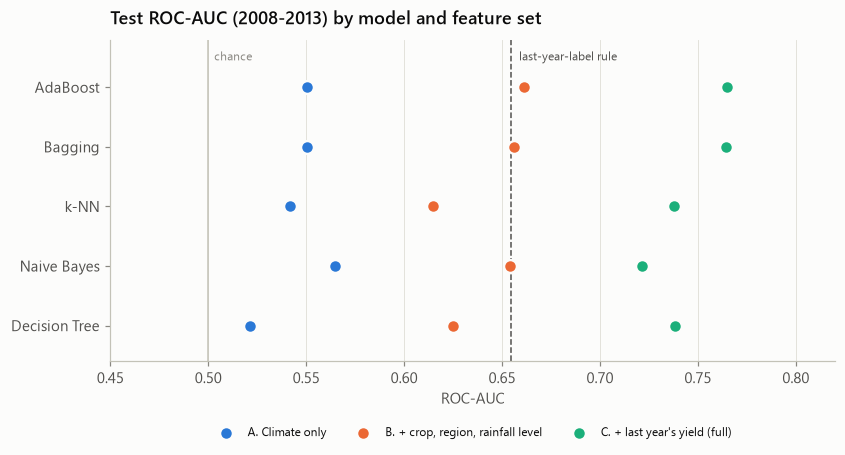

In [5]:
fs_names = list(mn.FEATURE_SETS)
models = list(mn.make_models([], []))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for i, fs in enumerate(fs_names):
    sub = table[table.feature_set == fs].set_index("model").loc[models]
    ax.scatter(sub["Test ROC-AUC"], range(len(models)), s=70, color=viz.SERIES[i], label=fs,
               zorder=3, edgecolor=viz.SURFACE, linewidth=1.5)
ax.axvline(0.5, color=viz.AXIS, lw=1)
ax.axvline(persistence["ROC-AUC"], color=viz.INK_2, lw=1, ls="--")
ax.text(persistence["ROC-AUC"] + 0.004, len(models) - 0.55, "last-year-label rule",
        fontsize=8, color=viz.INK_2)
ax.text(0.503, len(models) - 0.55, "chance", fontsize=8, color=viz.MUTED)
ax.set_yticks(range(len(models)), models)
ax.set_xlim(0.45, 0.82)
ax.set_ylim(-0.6, len(models) - 0.2)
ax.set(title="Test ROC-AUC (2008-2013) by model and feature set", xlabel="ROC-AUC")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8)
viz.save(fig, "fig11_ablation_roc_auc")
plt.show()

### 2.1 Full feature set: cross-validation vs. test

In [6]:
FULL = fs_names[-1]
num, cat = mn.FEATURE_SETS[FULL]
FEATURES = num + cat
full = table[table.feature_set == FULL].drop(columns="feature_set").set_index("model")
cols = ["threshold", "CV ROC-AUC", "CV F1", "Test Accuracy", "Test Precision", "Test Recall",
        "Test F1", "Test ROC-AUC", "Test PR-AUC"]
summary = pd.concat([full[cols], pd.DataFrame(
    {"threshold": 0.5, **{f"Test {k}": v for k, v in persistence.items()}},
    index=["Baseline: last year's label"])])
summary

,threshold,CV ROC-AUC,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
Decision Tree,0.750,0.752,0.373,0.886,0.380,0.368,0.374,0.738,0.319
Naive Bayes,0.960,0.734,0.365,0.857,0.294,0.381,0.331,0.722,0.254
k-NN,0.220,0.760,0.387,0.854,0.304,0.442,0.360,0.738,0.306
Bagging,0.550,0.775,0.383,0.865,0.330,0.442,0.377,0.764,0.338
AdaBoost,0.330,0.769,0.401,0.869,0.338,0.426,0.377,0.765,0.306
Baseline: last year's label,0.500,NaN,NaN,0.880,0.360,0.378,0.369,0.655,0.194


In [7]:
best_name = full["CV ROC-AUC"].idxmax()   # chosen on CV, not on test
best = results[(FULL, best_name)]
print(f"best model by CV ROC-AUC: {best_name} (threshold {best['threshold']:.2f})")
best["cv_folds"]

best model by CV ROC-AUC: Bagging (threshold 0.55)


,fold,val_years,ROC-AUC,PR-AUC
0,1,2000-2001,0.783,0.363
1,2,2002-2003,0.746,0.326
2,3,2004-2005,0.781,0.286
3,4,2006-2007,0.800,0.362


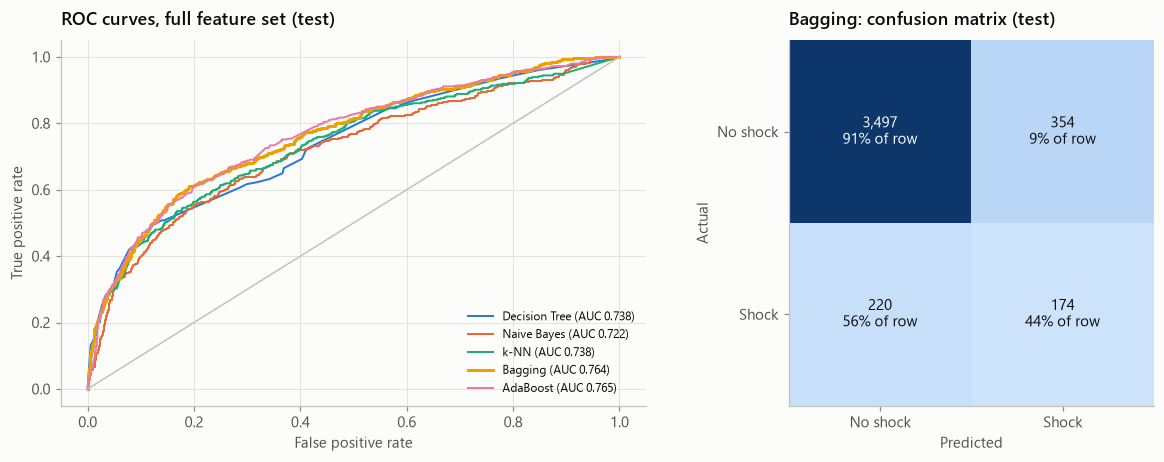

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), width_ratios=[1.35, 1])
ax = axes[0]
for i, m in enumerate(models):
    fpr, tpr, _ = roc_curve(test.is_shock, results[(FULL, m)]["test_proba"])
    ax.plot(fpr, tpr, color=viz.SERIES[i], lw=2 if m == best_name else 1.3,
            label=f"{m} (AUC {results[(FULL, m)]['test']['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=viz.AXIS, lw=1)
ax.set(title="ROC curves, full feature set (test)", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
pred = (best["test_proba"] >= best["threshold"]).astype(int)
cm = confusion_matrix(test.is_shock, pred)
ax.imshow(cm, cmap=viz.SEQUENTIAL)
labels = ["No shock", "Shock"]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j] / cm[i].sum():.0%} of row", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() * 0.5 else viz.INK, fontsize=10)
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set(title=f"{best_name}: confusion matrix (test)", xlabel="Predicted", ylabel="Actual")
ax.grid(False)
fig.tight_layout()
viz.save(fig, "fig12_roc_confusion")
plt.show()

## 3. Decision Tree rule extraction (IF-THEN)

A shallow tree (depth 4, at least 100 rows per leaf) is easy to read. Each leaf becomes a rule. Support
and shock rate are measured on the training years. The test shock rate checks whether the rule still holds
on the unseen years 2008-2013.

The tree is trained with balanced class weights, so a leaf predicts SHOCK whenever its shock rate is above the base rate (about 10 %), not only above 50 %.

In [9]:
def rule_table(feature_set, depth, min_leaf):
    num, cat = mn.FEATURE_SETS[feature_set]
    tree = mn.make_models(num, cat)["Decision Tree"].set_params(
        model__max_depth=depth, model__min_samples_leaf=min_leaf)
    tree.fit(train[num + cat], train.is_shock)
    tr_rules = mn.tree_rules(tree, train[num + cat], train.is_shock)
    te_rules = mn.tree_rules(tree, test[num + cat], test.is_shock)[["rule", "n_rows", "shock_rate"]]
    te_rules.columns = ["rule", "test_rows", "test_shock_rate"]
    rules = tr_rules.merge(te_rules, on="rule", how="left")
    proba = tree.predict_proba(test[num + cat])[:, 1]
    return tree, rules, roc_auc_score(test.is_shock, proba)

tree_full, rules_full, auc_full = rule_table(FULL, depth=4, min_leaf=100)
rules_full.to_csv(TABLES / "decision_tree_rules_full.csv", index=False)
print(f"shallow tree test ROC-AUC: {auc_full:.3f}   base shock rate (train): {train.is_shock.mean():.1%}")
rules_full[rules_full.prediction == "SHOCK"]

shallow tree test ROC-AUC: 0.747   base shock rate (train): 10.5%


,rule,prediction,n_rows,support,shock_rate,lift,test_rows,test_shock_rate
0,IF prev_yield_dev_pct <= -26.59 AND pesticide_intensity <= 2.22,SHOCK,201,0.017,0.597,5.672,70,0.714
1,IF -26.59 < prev_yield_dev_pct <= -19.72 AND region = Sub-Saharan Africa,SHOCK,118,0.010,0.441,4.187,50,0.280
2,IF prev_yield_dev_pct <= -26.59 AND pesticide_intensity > 2.22,SHOCK,389,0.032,0.440,4.176,135,0.400
3,IF -19.72 < prev_yield_dev_pct <= -8.64 AND rainfall_mm <= 1096.50 AND pesticide_intensity <= 2.30,SHOCK,149,0.012,0.403,3.826,43,0.163
4,IF -26.59 < prev_yield_dev_pct <= -19.72 AND region not in (Sub-Saharan Africa),SHOCK,202,0.017,0.307,2.916,51,0.235
5,IF -19.72 < prev_yield_dev_pct <= -14.00 AND rainfall_mm > 1096.50,SHOCK,194,0.016,0.227,2.155,64,0.188
6,IF -19.72 < prev_yield_dev_pct <= -8.64 AND rainfall_mm <= 1096.50 AND pesticide_intensity > 2.30,SHOCK,422,0.035,0.204,1.936,144,0.194
7,IF prev_yield_dev_pct > -8.64 AND rainfall_mm <= 1216.00 AND pesticide_intensity <= 4.33 AND crop_name = Sorghum,SHOCK,456,0.038,0.189,1.792,155,0.206
8,IF -14.00 < prev_yield_dev_pct <= -8.64 AND rainfall_mm > 1096.50,SHOCK,347,0.029,0.127,1.205,128,0.094
9,IF prev_yield_dev_pct > -2.10 AND rainfall_mm > 1216.00 AND temp_anomaly_c <= -0.17,SHOCK,116,0.010,0.112,1.065,34,0.000


### Climate-only rules

The same extraction using only the three proposal features shows which climate and input combinations
the tree finds, and how weak they are on their own.

In [10]:
tree_clim, rules_clim, auc_clim = rule_table(fs_names[0], depth=3, min_leaf=150)
rules_clim.to_csv(TABLES / "decision_tree_rules_climate_only.csv", index=False)
print(f"climate-only tree test ROC-AUC: {auc_clim:.3f}")
rules_clim

climate-only tree test ROC-AUC: 0.538


,rule,prediction,n_rows,support,shock_rate,lift,test_rows,test_shock_rate
0,IF pesticide_intensity <= 4.15 AND 0.91 < temp_anomaly_c <= 1.26,SHOCK,776,0.064,0.195,1.849,546,0.103
1,IF pesticide_intensity <= 4.15 AND temp_anomaly_c > 1.26,SHOCK,527,0.044,0.154,1.460,414,0.101
2,IF pesticide_intensity <= 1.82 AND temp_anomaly_c <= 0.91,SHOCK,1620,0.134,0.153,1.454,373,0.139
3,IF pesticide_intensity > 4.15 AND temp_anomaly_c <= -0.16,SHOCK,180,0.015,0.122,1.161,64,0.047
4,IF 4.15 < pesticide_intensity <= 4.89 AND temp_anomaly_c > 0.85,SHOCK,468,0.039,0.111,1.056,335,0.051
5,IF 1.82 < pesticide_intensity <= 4.15 AND temp_anomaly_c <= 0.91,no shock,6229,0.515,0.100,0.955,1758,0.102
6,IF pesticide_intensity > 4.89 AND temp_anomaly_c > 0.85,no shock,188,0.016,0.053,0.505,68,0.059
7,IF pesticide_intensity > 4.15 AND -0.16 < temp_anomaly_c <= 0.85,no shock,2106,0.174,0.039,0.374,687,0.060


## 4. What drives the best model? (permutation importance on the test years)

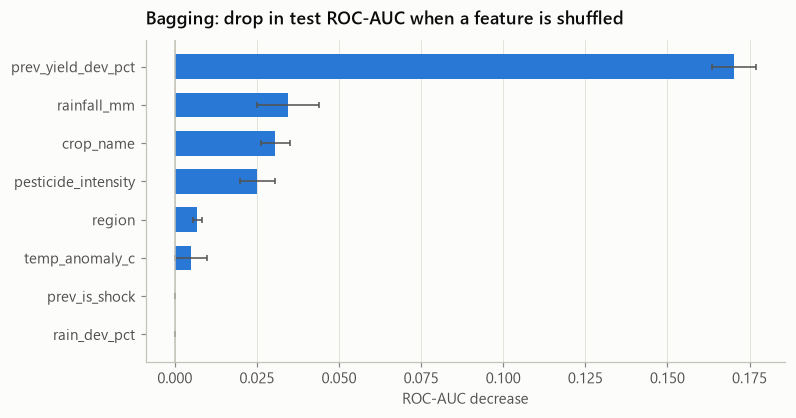

,feature,mean,std
4,prev_yield_dev_pct,0.170,0.007
3,rainfall_mm,0.034,0.009
6,crop_name,0.031,0.005
2,pesticide_intensity,0.025,0.005
7,region,0.007,0.001
1,temp_anomaly_c,0.005,0.005
5,prev_is_shock,0.000,0.000
0,rain_dev_pct,-0.000,0.000


In [11]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best["model"], test[FEATURES], test.is_shock, scoring="roc_auc",
                             n_repeats=10, random_state=cfg.RANDOM_STATE)
importance = (pd.DataFrame({"feature": FEATURES, "mean": imp.importances_mean, "std": imp.importances_std})
                .sort_values("mean"))
importance.to_csv(TABLES / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(importance.feature, importance["mean"], xerr=importance["std"], color=viz.SERIES[0],
        height=0.65, error_kw=dict(ecolor=viz.INK_2, lw=1, capsize=2))
ax.axvline(0, color=viz.AXIS, lw=1)
ax.set(title=f"{best_name}: drop in test ROC-AUC when a feature is shuffled", xlabel="ROC-AUC decrease")
ax.grid(axis="y", visible=False)
viz.save(fig, "fig13_permutation_importance")
plt.show()
importance.sort_values("mean", ascending=False)

## 5. Does performance differ by crop and region?

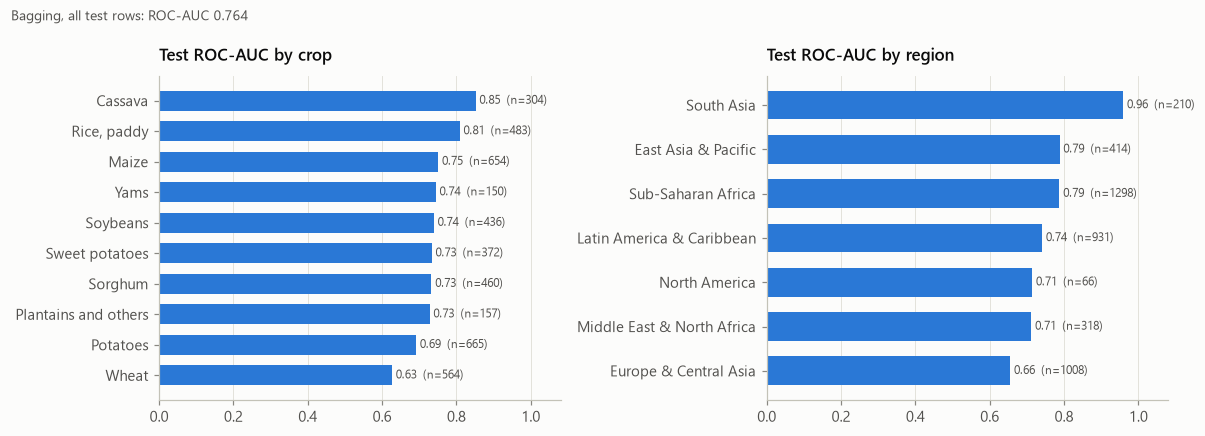

In [12]:
scored = test.assign(proba=best["test_proba"])

def auc_by(dim):
    out = []
    for key, g in scored.groupby(dim):
        if g.is_shock.nunique() == 2 and len(g) >= 50:
            out.append({dim: key, "rows": len(g), "shock_rate": g.is_shock.mean(),
                        "ROC-AUC": roc_auc_score(g.is_shock, g.proba)})
    return pd.DataFrame(out).sort_values("ROC-AUC")

by_crop, by_region = auc_by("crop_name"), auc_by("region")
overall_auc = best["test"]["ROC-AUC"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, df, dim in [(axes[0], by_crop, "crop_name"), (axes[1], by_region, "region")]:
    ax.barh(df[dim], df["ROC-AUC"], color=viz.SERIES[0], height=0.65)
    for y, (v, n) in enumerate(zip(df["ROC-AUC"], df.rows)):
        ax.text(v + 0.01, y, f"{v:.2f}  (n={n})", va="center", fontsize=8, color=viz.INK_2)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
axes[0].set_title("Test ROC-AUC by crop", fontsize=11)
axes[1].set_title("Test ROC-AUC by region", fontsize=11)
fig.suptitle(f"{best_name}, all test rows: ROC-AUC {overall_auc:.3f}", x=0.01, ha="left",
             fontsize=9, color=viz.INK_2)
fig.tight_layout()
viz.save(fig, "fig14_auc_by_crop_region")
plt.show()
pd.concat([by_crop.rename(columns={"crop_name": "group"}).assign(dimension="crop"),
           by_region.rename(columns={"region": "group"}).assign(dimension="region")]).to_csv(
    TABLES / "auc_by_crop_region.csv", index=False)

## 6. Regression baseline: linear regression on the yield deviation

The target is `yield_dev_pct`, winsorised at the 1st and 99th training percentiles because a few series
jump several hundred percent (data revisions, tiny harvests). The same bounds are applied to the test
target. The regression output is also scored as a shock detector (predicted deviation ≤ -15 %).

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

lo, hi = train.yield_dev_pct.quantile([0.01, 0.99])
y_tr, y_te = train.yield_dev_pct.clip(lo, hi), test.yield_dev_pct.clip(lo, hi)

reg_rows, regs = [], {}
for fs in fs_names:
    num_r, cat_r = mn.FEATURE_SETS[fs]
    reg = Pipeline([("prep", mn.preprocessor(num_r, cat_r, scale=True)), ("model", LinearRegression())])
    reg.fit(train[num_r + cat_r], y_tr)
    p = reg.predict(test[num_r + cat_r])
    regs[fs] = reg
    reg_rows.append({"model": f"Linear regression, {fs}", "R2": r2_score(y_te, p),
                     "MAE": mean_absolute_error(y_te, p), "RMSE": mean_squared_error(y_te, p) ** 0.5,
                     "shock ROC-AUC (score = -prediction)": roc_auc_score(test.is_shock, -p)})
naive = np.full(len(y_te), y_tr.mean())
reg_rows.append({"model": "Naive: training mean", "R2": r2_score(y_te, naive),
                 "MAE": mean_absolute_error(y_te, naive), "RMSE": mean_squared_error(y_te, naive) ** 0.5,
                 "shock ROC-AUC (score = -prediction)": 0.5})
reg_table = pd.DataFrame(reg_rows).set_index("model")
reg_table.to_csv(TABLES / "regression_results.csv")
reg_table

,R2,MAE,RMSE,shock ROC-AUC (score = -prediction)
model,,,,
"Linear regression, A. Climate only",-0.009,13.314,20.335,0.526
"Linear regression, B. + crop, region, rainfall level",-0.005,13.241,20.290,0.550
"Linear regression, C. + last year's yield (full)",0.143,11.885,18.733,0.678
Naive: training mean,-0.001,13.241,20.249,0.500


In [14]:
reg = regs[FULL]
names = reg.named_steps["prep"].get_feature_names_out()
coef = pd.Series(reg.named_steps["model"].coef_, index=names)
print(f"intercept: {reg.named_steps['model'].intercept_:.2f} percentage points")
print("numeric coefficients (per 1 standard deviation of the feature, in percentage points of yield deviation):")
coef[num].sort_values()

intercept: 4.68 percentage points
numeric coefficients (per 1 standard deviation of the feature, in percentage points of yield deviation):


temp_anomaly_c        -1.005
rainfall_mm           -0.226
pesticide_intensity   -0.114
prev_is_shock          0.104
rain_dev_pct           0.137
prev_yield_dev_pct     7.775
dtype: float64

In [15]:
p = reg.predict(test[FEATURES])
m = mn.classification_metrics(test.is_shock, (p <= cfg.SHOCK_THRESHOLD_PCT).astype(float), 0.5)
pd.Series({k: m[k] for k in ["Accuracy", "Precision", "Recall", "F1"]},
          name="regression used as a classifier (pred <= -15 %)")

Accuracy    0.910
Precision   0.667
Recall      0.056
F1          0.103
Name: regression used as a classifier (pred <= -15 %), dtype: float64

## 7. Takeaways

* **Climate alone barely beats chance.** The three proposal features (rainfall deviation, temperature
  anomaly, pesticide intensity) give a test ROC-AUC of 0.52-0.57. National annual means are too coarse
  to capture a growing-season shock, and the rainfall deviation is empty (notebook 01).
* **Context and history make the model useful.** Adding crop, region and rainfall level raises the
  ROC-AUC to 0.62-0.66. Adding last year's yield outcome raises it to 0.72-0.77. The best model by CV
  is **Bagging** (CV ROC-AUC 0.775, test 0.764, PR-AUC 0.338, recall 0.44, precision 0.33). AdaBoost is
  within 0.001 of it on test. The CV folds are stable (0.75-0.80), so the model does not depend on a
  lucky period.
* **The naive persistence rule is a strong baseline.** "Predict a shock after a shock" reaches F1 0.369.
  The ensembles beat it mainly at *ranking* risk (ROC-AUC 0.76 vs 0.66, PR-AUC 0.34 vs 0.19); their F1
  is only slightly higher. That is the honest size of the gain.
* **IF-THEN rules.** The best rule says: *if last year's yield was more than 26.6 % below baseline and
  pesticide intensity is low (≤ 2.22), then shock.* It holds 59.7 % of the time in training (5.7x the
  base rate) and 71.4 % in the test years. The climate-only rules do not hold up. "Anomaly
  0.91-1.26 °C and pesticide ≤ 4.15" gives 19.5 % shocks in training but only 10.3 % in the test years,
  because warming moves the anomaly distribution, so a fixed cut-off drifts.
* **Importance.** Shuffling last year's deviation costs 0.17 ROC-AUC. Rainfall level (0.034), crop
  (0.031) and pesticide intensity (0.025) matter less, temperature anomaly hardly at all (0.005), and
  rainfall deviation not at all.
* **By crop and region.** Test ROC-AUC runs from 0.63 (wheat) to 0.85 (cassava), and from 0.66
  (Europe & Central Asia) to 0.79 (Sub-Saharan Africa). South Asia's 0.96 rests on only 7 shocks.
* **Regression baseline.** Linear regression explains almost nothing with climate alone (R² ≈ 0) and
  14 % of the variance with history (R² 0.143). The temperature coefficient is negative (−1.0
  percentage points per standard deviation): hotter years have lower yields relative to baseline. Used as
  a shock detector it catches only 5.6 % of shocks, because it predicts values close to the mean.
  Framing the problem as classification is the right choice.